In [53]:
#Remove variables from workspace
%reset

Nothing done.


In [54]:
%matplotlib inline

import os
import scipy.io
import fnmatch
from statistics import mean
import pickle
import fNIRSData
import numpy as np
import skfda
import matplotlib.pyplot as plt
from skfda.exploratory.visualization import FPCAPlot
from skfda.preprocessing.dim_reduction import FPCA
from skfda.preprocessing.registration import LeastSquaresShiftRegistration
from skfda.representation.basis import (
    BSplineBasis,
    FourierBasis,
    MonomialBasis,
)
import pandas as pd

##If you need to change anything in 'fNIRSData' before running again:
#import importlib
#importlib.reload(fNIRSData)

In [55]:
grid_points = np.arange(-20, 182, 1)  # Grid points of the curves

matrix = np.empty([25, 202])

nfPCs = 5

In [56]:
for trial in range(1,26):
    #load trial data
    trialDF = fNIRSData.getTrialTS('test8moDataFrame.pkl', 1, 3, trial)
    #find number of participants and use it to create empty matrix for storage
    numParts = max((trialDF['Time series']).shape)
    trialMat = np.empty([numParts, len(trialDF['Time series'].iloc[0])])
    for i in range(0, numParts):
        y = (trialDF['Time series'].iloc[i-1])
        coeff = np.polyfit(grid_points, y, 1)
        yPoly = np.polyval(coeff, grid_points)
        trialMat[i] = y - yPoly

    #plt.plot(trialMat)

    meanMat = trialMat.mean(axis=0)

    #print(shape(meanMat))
        
    FDtemp = skfda.FDataGrid(
        data_matrix=trialMat,
        grid_points=grid_points,
    )

    #plotting the mean calculated in each of the following ways shows that the problem of infinitesimal values occurs previously
    meanFDtemp = skfda.exploratory.stats.mean(FDtemp)
    #meanOrig = trialMat.mean(axis=0)
    matrix[trial-1] = meanFDtemp.data_matrix[0, :, 0]
    #matrix[trial-1] = meanOrig

    #plots each mean trial haemodynamic response in the event that issue of infinite/infinitesimal values occur
    #plt.plot(meanOrig) # - simpler: without shirting in time to pre-stimulus baseline
    #meanFDtemp.plot() # - shifts data horizontally such that x-axis correct


Look at data in the event that issue of infinite/infinitesimal values occur:

In [57]:
#largeMatVals = np.where(matrix > 100)
#largeMatVals

In [58]:
#largeOrigMatVals = np.where(meanOrig > 100)
#largeOrigMatVals

<Axes: >

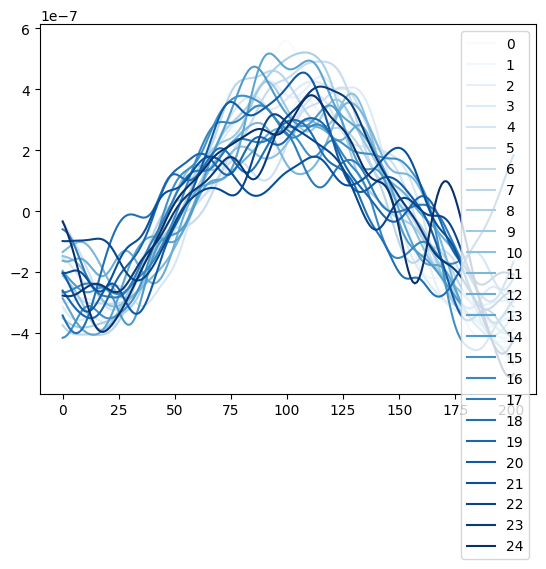

In [59]:
trialFrame = pd.DataFrame(data=matrix)
trialFrame = trialFrame.T
trialFrame.plot(
    colormap = plt.cm.Blues
)

Plot without trial numbers if convenient:

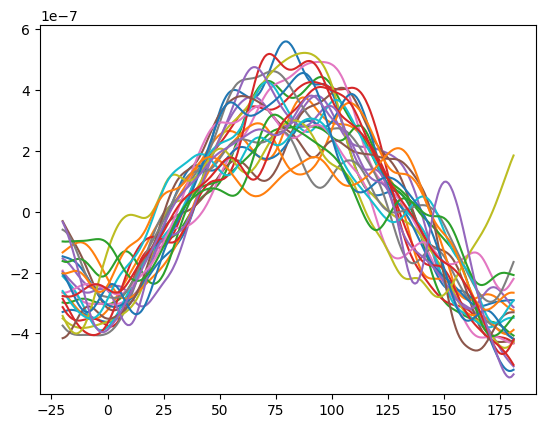

In [60]:
fd = skfda.FDataGrid(
    data_matrix=matrix,
    grid_points=grid_points,
)

fd.plot()
print()

Plot the mean of these functions:

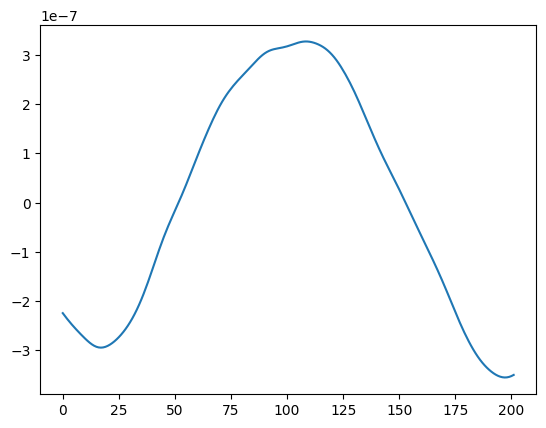

In [42]:
matMean = np.mean(matrix, axis = 0)
plt.plot(matMean)

Find and plot the fPCs:
(alter n components if necessary i.e. % of explained variance < 85%)

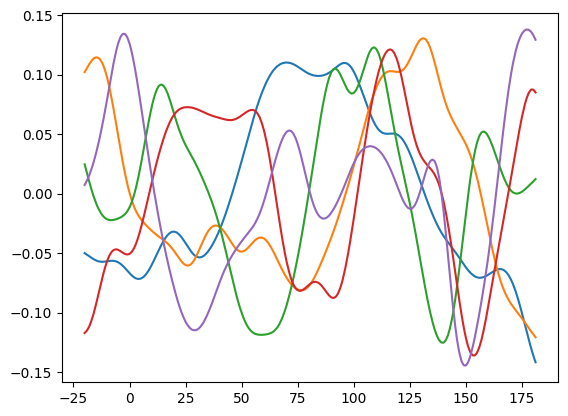

In [43]:
fpca_discretized = FPCA(n_components=nfPCs)
fpca_discretized.fit(fd)

comps = fpca_discretized.components_

(-(fpca_discretized.components_)).plot()
print()

Plot each fPC individually if useful:

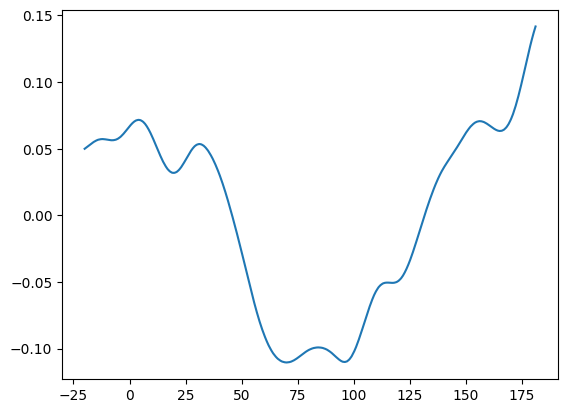

In [52]:
((fpca_discretized.components_[0])).plot()
#((fpca_discretized.components_[1])).plot(color = 'orange')
#((fpca_discretized.components_[2])).plot(color = 'green')
#((fpca_discretized.components_[3])).plot()
#((fpca_discretized.components_[4])).plot()
print()

The singular (eigen-) values:

In [45]:
print(fpca_discretized.singular_values_)

[3.87637475e-06 2.92115360e-06 2.13315714e-06 1.89185450e-06
 1.75422451e-06]


Define 'scores', a (25x5) numpy array containing the fPC scores pertaining to the trial-by-trial haemodynamic responses in the K-L expansion.
<br>It can be indexed using [i][j], to find the relative contribution (score) of the (j+1)th fPC to the (i+1)th trial/response:

In [46]:
scores = fpca_discretized.transform(fd)
scores[5][2]

-6.212178638746941e-07

'comps' is an 'FDataGrid' object created by skfda and more difficult to index, but can be multiplied by scalars:
<br> (means the elements in 'scores' can be used to reconstruct approximations using the first PCs)
<br> comps[j] indexes information for the (j+1)th fPC

In [47]:
#comps[0]

In [48]:
#2*(comps[0])

Store reconstructed data using all calculated fPCs:

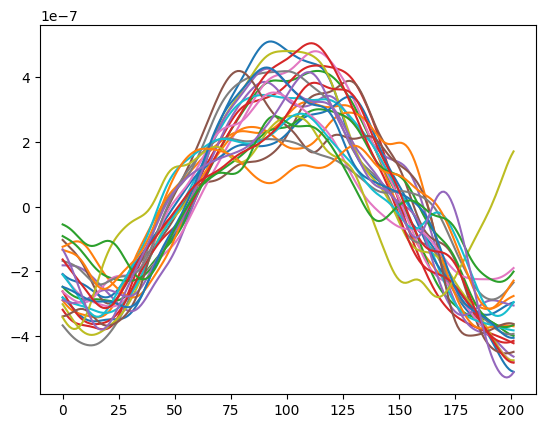

In [49]:

for j in range(0,25):
    trialResp = []
    for i in range(0, nfPCs):
        trialResp.append((scores[j][i])*(comps[i].data_matrix[0]))
        #test = test + (scores[j][i])*(comps[i].data_matrix[0])
        #test = (scores[j][0])*(comps[0].data_matrix[0])+(scores[j][1])*(comps[1].data_matrix[0])+(scores[j][2])*(comps[2].data_matrix[0])+(scores[j][3])*(comps[3].data_matrix[0])+ (scores[j][4])*(comps[4].data_matrix[0])
    
    dataReconFull = np.sum(trialResp, axis = 0)
    dataReconFull = dataReconFull.transpose()[0]
    dataReconFull = np.add(dataReconFull, matMean)
    plt.plot(dataReconFull)

Comparing with original plot for data, can see that some of the high frequency variations have been dampened, with the consequence that the overall peak magnitude of the data has also reduced.

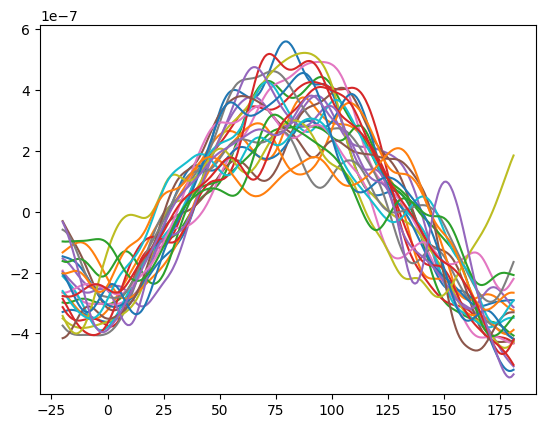

In [50]:
fd.plot()
print()

Using just the first PC does smooth the data significantly, however, and permit the observation of changes due to this source of variation only:

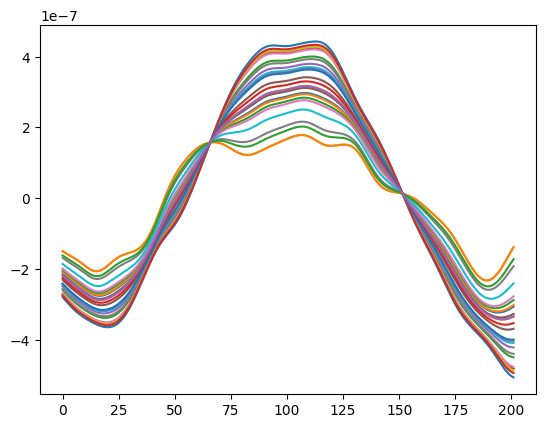

In [51]:
for j in range(0,25):
    trialResp = []
    for i in range(0, 1):
        trialResp.append((scores[j][i])*(comps[i].data_matrix[0]))
        #test = test + (scores[j][i])*(comps[i].data_matrix[0])
        #test = (scores[j][0])*(comps[0].data_matrix[0])+(scores[j][1])*(comps[1].data_matrix[0])+(scores[j][2])*(comps[2].data_matrix[0])+(scores[j][3])*(comps[3].data_matrix[0])+ (scores[j][4])*(comps[4].data_matrix[0])
    
    dataReconFirst = np.sum(trialResp, axis = 0)
    dataReconFirst = dataReconFirst.transpose()[0]
    dataReconFirst = np.add(dataReconFirst, matMean)
    plt.plot(dataReconFirst)